In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
sns.set_style("whitegrid"); plt.rcParams["figure.figsize"]=(10,6)
print("Ready.")

Ready.


In [2]:
def find_dir():
    for root in ["/kaggle/input", ".", "/media/hdd/cybersec_ai/datasets"]:
        hits = glob.glob(os.path.join(root, "**", "*ISCX.csv"), recursive=True)
        if hits:
            return sorted(set(os.path.dirname(h) for h in hits), key=len)[0]
    return "."

data_dir = find_dir()
files = sorted(glob.glob(os.path.join(data_dir, "*.csv")))
print("Found", len(files), "CSV files in", data_dir)

frames = []
for f in files:
    d = pd.read_csv(f, low_memory=False)
    d.columns = d.columns.str.strip()
    if len(d) > 40000:
        d = d.sample(40000, random_state=42)
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
print("Combined (sampled) shape:", df.shape)

# /kaggle/input/datasets/someshwarsa/cic-ids-2017

Found 8 CSV files in /kaggle/input/datasets/someshwarsa/cic-ids-2017
Combined (sampled) shape: (320000, 79)


In [3]:
# CIC-IDS-2017 has some inf / NaN values from rate computations
df = df.replace([np.inf, -np.inf], np.nan).dropna()
df["Label"] = df["Label"].astype(str).str.strip()
print("Rows after cleaning:", len(df))
print("\nAttack types present:")
print(df["Label"].value_counts())

Rows after cleaning: 319727

Attack types present:
Label
BENIGN                        258121
DDoS                           22808
PortScan                       22187
DoS Hulk                       13203
FTP-Patator                      732
DoS GoldenEye                    565
SSH-Patator                      531
Bot                              382
Web Attack � Brute Force         367
DoS Slowhttptest                 329
DoS slowloris                    327
Web Attack � XSS                 164
Web Attack � Sql Injection         5
Infiltration                       4
Heartbleed                         2
Name: count, dtype: int64


/tmp/ipykernel_58/2099226076.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vc.values, y=vc.index, palette="rocket")


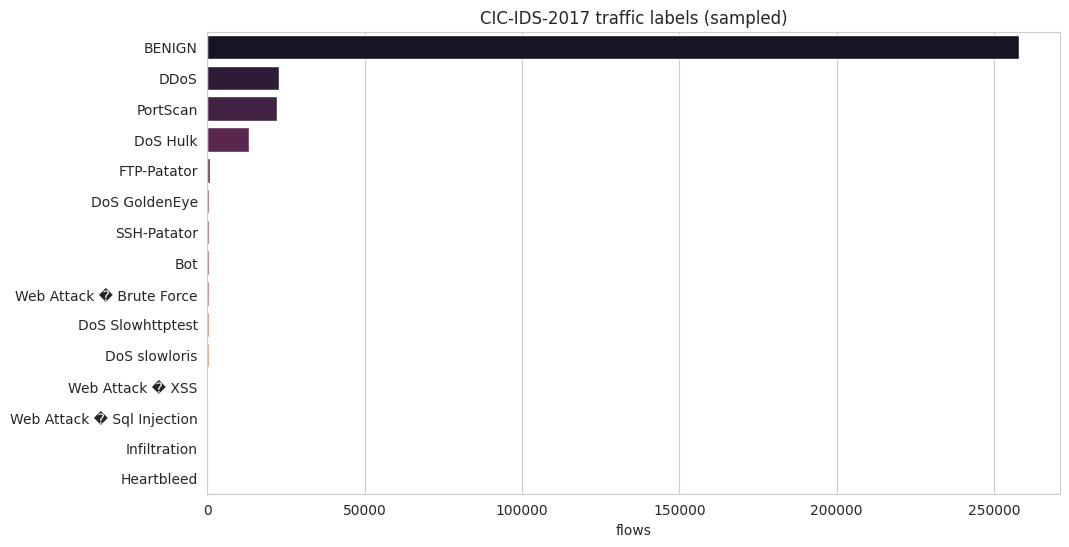

In [4]:
plt.figure(figsize=(11,6))
vc = df["Label"].value_counts()
sns.barplot(x=vc.values, y=vc.index, palette="rocket")
plt.title("CIC-IDS-2017 traffic labels (sampled)"); plt.xlabel("flows"); plt.ylabel("")
plt.show()

In [5]:
y_bin = df["Label"].apply(lambda x: "BENIGN" if x == "BENIGN" else "ATTACK")
X = df.select_dtypes("number")
Xtr, Xte, ytr, yte = train_test_split(X, y_bin, test_size=0.2,
                                      random_state=42, stratify=y_bin)
bin_model = HistGradientBoostingClassifier(max_iter=200, random_state=42)
bin_model.fit(Xtr, ytr)
bpred = bin_model.predict(Xte)
bacc = accuracy_score(yte, bpred)
print(f"BINARY TEST ACCURACY: {bacc:.4f}  ({bacc:.2%})\n")
print(classification_report(yte, bpred, digits=4))

BINARY TEST ACCURACY: 0.9989  (99.89%)

              precision    recall  f1-score   support

      ATTACK     0.9964    0.9980    0.9972     12321
      BENIGN     0.9995    0.9991    0.9993     51625

    accuracy                         0.9989     63946
   macro avg     0.9979    0.9985    0.9982     63946
weighted avg     0.9989    0.9989    0.9989     63946



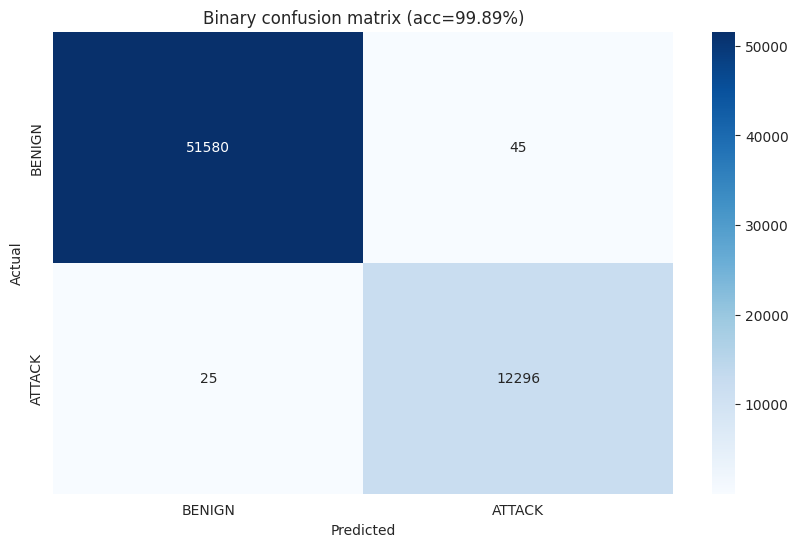

In [6]:
cm = confusion_matrix(yte, bpred, labels=["BENIGN","ATTACK"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["BENIGN","ATTACK"], yticklabels=["BENIGN","ATTACK"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Binary confusion matrix (acc={bacc:.2%})"); plt.show()

In [7]:
counts = df["Label"].value_counts()
keep = counts[counts >= 500].index
sub = df[df["Label"].isin(keep)]
Xm = sub.select_dtypes("number")
ym = sub["Label"]
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.2,
                                      random_state=42, stratify=ym)
cat_model = HistGradientBoostingClassifier(max_iter=200, random_state=42)
cat_model.fit(Xtr, ytr)
cpred = cat_model.predict(Xte)
cacc = accuracy_score(yte, cpred)
print(f"MULTI-CLASS TEST ACCURACY: {cacc:.4f}  ({cacc:.2%})\n")
print(classification_report(yte, cpred, digits=4, zero_division=0))

MULTI-CLASS TEST ACCURACY: 0.9984  (99.84%)

               precision    recall  f1-score   support

       BENIGN     0.9992    0.9988    0.9990     51625
         DDoS     1.0000    0.9976    0.9988      4562
DoS GoldenEye     0.8504    0.9558    0.9000       113
     DoS Hulk     0.9947    0.9943    0.9945      2641
  FTP-Patator     0.9932    1.0000    0.9966       146
     PortScan     0.9933    0.9977    0.9955      4437
  SSH-Patator     0.9906    0.9906    0.9906       106

     accuracy                         0.9984     63630
    macro avg     0.9745    0.9907    0.9821     63630
 weighted avg     0.9984    0.9984    0.9984     63630



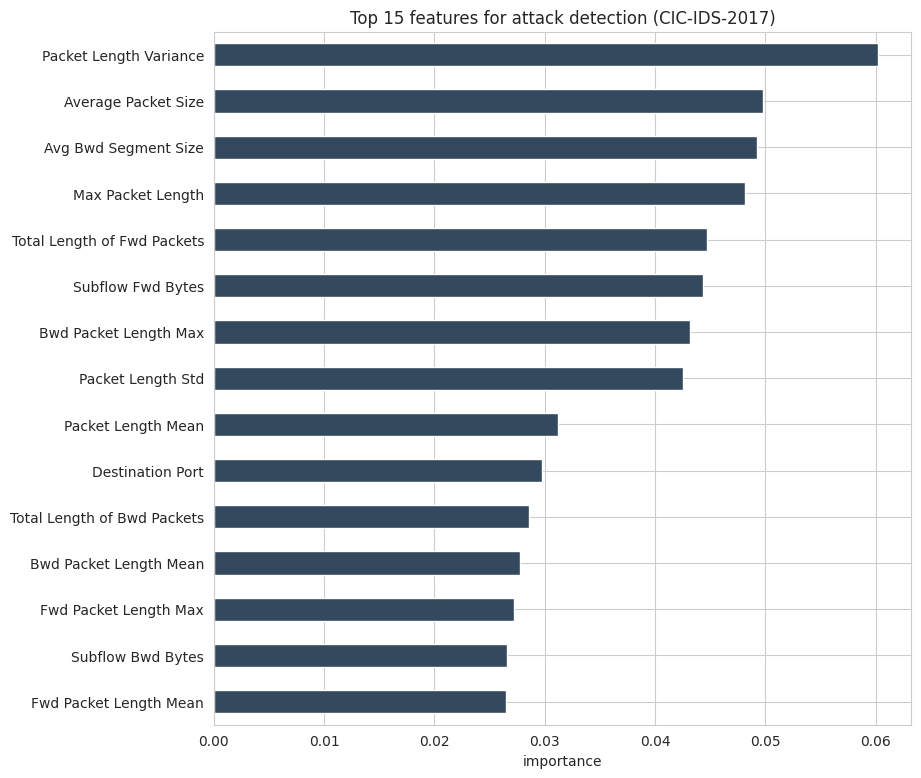

In [8]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(Xtr, ytr)
imp = pd.Series(rf.feature_importances_, index=Xm.columns).sort_values()
plt.figure(figsize=(9,9))
imp.tail(15).plot(kind="barh", color="#34495e")
plt.title("Top 15 features for attack detection (CIC-IDS-2017)")
plt.xlabel("importance"); plt.show()